# Household Expenditure Structure: Bulgaria vs European Countries

Final exam project, Data Science module.

**Author:** Yana Atanasova  
**Date:** November 2026

## 1. Introduction and Problem Formulation



### 1.1 Motivation

The share of a household's budget spent on food is a classic indicator of living standards.
Engel's law states that this share falls as income rises. Bulgaria is one of the lower-income
members of the European Union, so Bulgarian households are expected to spend a larger part of
their budget on necessities. Knowing how large this difference is, how it has changed, and which
countries Bulgaria resembles is useful for understanding how changes in prices and incomes
affect households.

### 1.2 Research questions

1. How does the structure of household spending in Bulgaria differ from that of other countries?
2. How has it changed over time?
3. Which countries are closest to Bulgaria in their spending profile?
4. Does Engel's law hold across countries, and how does Bulgaria compare with the relationship?

### 1.3 Data and scope

The analysis combines two independent sources (details in section 2):

- **Eurostat, Household Budget Survey (HBS):** the structure of household consumption
  expenditure in 12 COICOP groups, for survey waves between 1988 and 2020.
- **World Bank, World Development Indicators:** GDP per capita, PPP (constant 2021 international dollars), used as a measure of income.

The main analysis uses the waves 2005, 2010, 2015 and 2020 (118 country-years), because earlier
waves are not comparable (see section 3.4).

### 1.4 Mathematical formulation

For country $c$ in wave $t$ the spending profile is a vector
$s_{ct} = (s_{ct,1}, \dots, s_{ct,12})$ of shares with $s_{ct,k} \ge 0$ and $\sum_k s_{ct,k} = 100\%$.
Housing includes imputed rent $I_{ct}$ (the rent owner-occupiers would pay to themselves), which
is not reported consistently. To make profiles comparable, it is removed from the housing group
$h$ and from the total:

$$ s'_{ct,k} = 100 \cdot \frac{v_{ct,k} - I_{ct}\,\mathbb{1}[k = h]}{1000 - I_{ct}}, $$

where $v_{ct,k}$ is the share in per mille.

- **Similarity:** the distance between two countries is the Euclidean distance
  $d(a, b) = \sqrt{\sum_k (a_k - b_k)^2}$.
- **Clustering:** K-means with $k$ clusters minimises
  $\sum_{j=1}^{k} \sum_{x \in C_j} \lVert x - \mu_j \rVert^2$ on standardised shares
  $z = (x - \bar{x}) / \sigma_x$; $k$ is chosen with the silhouette score
  $s(i) = \dfrac{b(i) - a(i)}{\max(a(i), b(i))}$, where $a(i)$ is the mean distance to the own
  cluster and $b(i)$ the mean distance to the nearest other cluster.
- **Visualisation:** principal component analysis projects the standardised profiles onto the
  eigenvectors of their covariance matrix with the largest eigenvalues.
- **Engel curve:** with $s_i$ the food share and $G_i$ GDP per capita, we fit by ordinary least
  squares $s_i = \beta_0 + \beta_1 \ln G_i + \varepsilon_i$ and
  $\ln s_i = \beta_0 + \beta_1 \ln G_i + \varepsilon_i$. In the second model $\beta_1$ is an
  elasticity. Engel's law predicts $\beta_1 < 0$.

### 1.5 Assumptions, constraints and limitations of the approach

- The analysis uses country-level aggregates, not household-level data. Studies of Engel
  curves often use household microdata, which allows controlling for household size and for the
  income distribution within a country; aggregates cannot, so conclusions are about countries,
  not about individual households.
- GDP per capita is used as a proxy for household income.
- Survey waves are about five years apart and the set of countries differs between waves.
- Countries with missing imputed rent are excluded from the adjusted analysis.
- The regression shows association, not causation.

### 1.6 Structure of the notebook

Sections 2-4 load, clean, validate and merge the data; section 5 explores it; section 6
compares Bulgaria with the other countries; section 7 clusters the countries; section 8 fits the
Engel curve; section 9 gives the conclusions and limitations; section 10 lists the sources.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import statsmodels.formula.api as smf
import statsmodels.api as sm

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# Project root: works from the repo root and from the notebooks/ folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"

## 2. Data Loading

**Source 1: Eurostat, Household Budget Survey (HBS).**
Table `hbs_str_t211`: structure of consumption expenditure by COICOP category (in per mille).

- URL: https://ec.europa.eu/eurostat/databrowser/view/hbs_str_t211/default/table?lang=en
- Downloaded: 15 November 2026 (SDMX-CSV 1.0, full dataset, gzip-compressed)
- File: `data/raw/hbs_str_t211.csv.gz` (never modified)
- Coverage: 7 survey waves (1988, 1994, 1999, 2005, 2010, 2015, 2020), 38 geographic entities, 218 COICOP categories

**Source 2: World Bank, World Development Indicators.**
Indicator `NY.GDP.PCAP.PP.KD`: GDP per capita, PPP (constant 2021 international $).

- URL: https://data.worldbank.org/indicator/NY.GDP.PCAP.PP.KD
- Downloaded: 24 November 2026 (CSV)
- File: `data/raw/API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_66103.csv` (never modified)
- Coverage: 266 countries and aggregates. PPP values are available from 1990.

The indicator uses constant 2021 international dollars, allowing comparisons over time without the effect of inflation.

The two sources are independent (an EU statistical office and an international development institution). They are joined by country and year in section 4.

In [2]:
# Eurostat table hbs_str_t211 (downloaded as a gzip-compressed CSV)
hbs = pd.read_csv(RAW_DIR / "hbs_str_t211.csv.gz")

print(hbs.shape)
hbs.head(10)

(29425, 10)


,DATAFLOW,LAST UPDATE,freq,coicop,unit,geo,TIME_PERIOD,OBS_VALUE,OBS_FLAG,CONF_STATUS
0,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,1994,154,NaN,NaN
1,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,1999,134,NaN,NaN
2,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2005,130,NaN,NaN
3,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2010,121,NaN,NaN
4,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2015,118,NaN,NaN
5,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Austria,2020,120,NaN,NaN
6,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,1988,161,NaN,NaN
7,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,1994,120,NaN,NaN
8,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,1999,133,NaN,NaN
9,ESTAT:HBS_STR_T211(1.0),15/10/25 23:00:00,Annual,Food and non-alcoholic beverages,Per mille,Belgium,2005,135,NaN,NaN


In [3]:
# World Bank: GDP per capita, PPP (constant 2021 international $),
# indicator NY.GDP.PCAP.PP.KD.
# The file name contains a version number, so it is found with a pattern.
wb_path = next(RAW_DIR.glob("API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_*.csv"))
print(wb_path.name)

# The first 4 lines of the World Bank CSV are metadata, not data
wb = pd.read_csv(wb_path, skiprows=4)

print(wb.shape)
wb.head()

API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_66103.csv
(266, 71)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,...,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,38195.317608,38182.392526,40101.787613,38926.475000,38664.399510,39562.448848,39982.511992,35074.684122,34037.542321,34926.100892,34058.310233,35711.929051,35837.324093,36753.404173,36926.113069,38213.289239,39378.228411,39754.560072,30408.827090,35207.170909,39083.461640,42783.248907,45428.002728,NaN,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3350.693839,3357.783916,3457.688721,3578.212979,3718.693485,3867.508788,3935.022918,3870.961866,3978.129571,4033.187324,4051.445711,4126.335395,4186.248511,4207.363579,4210.935695,4223.188050,4229.839634,4200.531044,3978.133502,4049.969513,4098.126192,4076.224898,4099.889812,4164.679177,NaN
2,Afghanistan,AFG,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1774.308743,1815.928200,1776.918207,1908.114782,1929.723897,2155.353068,2191.504356,2565.022086,2848.586061,2757.052587,2985.319145,3046.579931,3017.942544,2967.692067,2958.785399,2952.998916,2902.392113,2927.245144,2769.685745,2144.166570,1981.710168,1983.812620,1964.452289,NaN,NaN
3,Africa Western and Central,AFW,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4299.849751,4423.570413,4648.606280,4782.442140,4899.657136,5023.698823,5188.671014,5362.153606,5582.430944,5698.389500,5823.418946,6009.651861,6183.241162,6194.434494,6034.826989,6009.516114,6026.527572,6070.284769,5698.766702,5702.134886,5818.483224,5886.796636,6009.084662,6139.587294,NaN
4,Angola,AGO,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,7521.735988,7516.813915,8079.526133,8892.921061,9586.175421,10434.708722,11131.631015,10930.253120,11074.072381,11034.591969,11516.813325,11622.978346,11718.428683,11389.760955,10963.996789,10565.167648,10154.838923,9712.979449,8904.949006,8720.187687,8750.993630,8597.538788,8752.797471,8760.190820,NaN


## 3. Data Cleaning and Validation


### 3.1 Selecting countries and top-level categories

In [4]:
# How many unique values does each dimension have?
for col in ["freq", "unit", "coicop", "geo", "TIME_PERIOD"]:
    print(col, hbs[col].nunique(), "unique values")
    print(sorted(hbs[col].unique())[:15], "\n")

freq 1 unique values
['Annual'] 

unit 1 unique values
['Per mille'] 

coicop 218 unique values
['Accommodation services', 'Actual rentals for housing', 'Actual rentals paid by tenants', 'Alcoholic beverages', 'Alcoholic beverages, tobacco and narcotics', 'Animal drawn vehicles', 'Apples (fresh, chilled or frozen)', 'Audio-visual, photographic and information processing equipment', "Baker's yeast, dessert preparations, soups", 'Bananas (fresh, chilled or frozen)', 'Beef and veal', 'Beer', 'Berries (fresh, chilled or frozen)', 'Bicycles', 'Books'] 

geo 38 unique values
['Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'European Union - 15 countries (1995-2004)', 'European Union - 25 countries (2004-2006)', 'European Union - 27 countries (2007-2013)', 'European Union - 27 countries (from 2020)', 'Finland', 'France', 'Germany'] 

TIME_PERIOD 7 unique values
[np.int64(1988), np.int64(1994), np.int64(1999), np.int64(2005), np.int64(2010), np.int64(201

In [5]:
# The 12 top-level COICOP groups
main_groups = [
    "Food and non-alcoholic beverages",
    "Alcoholic beverages, tobacco and narcotics",
    "Clothing and footwear",
    "Housing, water, electricity, gas and other fuels",
    "Furnishings, household equipment and routine household maintenance",
    "Health",
    "Transport",
    "Communications",
    "Recreation and culture",
    "Education",
    "Restaurants and hotels",
    "Miscellaneous goods and services",
]

# Keep only the 12 main groups and only countries (drop EU aggregates)
df = hbs.loc[
    hbs["coicop"].isin(main_groups)
    & ~hbs["geo"].str.contains("European Union|Euro area"),
    ["geo", "TIME_PERIOD", "coicop", "OBS_VALUE"],
].dropna(subset=["OBS_VALUE"]).copy()

df = df.rename(columns={"geo": "country", "TIME_PERIOD": "year", "coicop": "category"})
df["share_pct"] = df["OBS_VALUE"] / 10   # per mille -> percent

print(df.shape)
print(df["country"].nunique(), "countries")
df.head()

(2135, 5)
34 countries


,country,year,category,OBS_VALUE,share_pct
0,Austria,1994,Food and non-alcoholic beverages,154,15.4
1,Austria,1999,Food and non-alcoholic beverages,134,13.4
2,Austria,2005,Food and non-alcoholic beverages,130,13.0
3,Austria,2010,Food and non-alcoholic beverages,121,12.1
4,Austria,2015,Food and non-alcoholic beverages,118,11.8


### 3.2 Validation of expenditure totals

In [6]:
# Validation: the 12 shares of each country-year should add up to about 1000 per mille
check = df.groupby(["country", "year"]).agg(
    total=("OBS_VALUE", "sum"),
    n_groups=("category", "nunique"),
)

# Problematic rows: a missing group, or a total far from 1000
problems = check[(check["n_groups"] != 12) | ((check["total"] - 1000).abs() > 5)]
print(len(check), "country-year combinations,", len(problems), "with a problem")
problems

178 country-year combinations, 5 with a problem


total  n_groups
country year                 
Estonia 1999    970        12
Germany 1988    999        11
Poland  2005   1008        12
Sweden  2005    919        12
        2015    992        12

In [7]:
# Exclude the incomplete observation (Germany 1988: 11 of 12 groups)
# and the most inconsistent one (Sweden 2005: total of only 919 per mille)
exclude = [("Germany", 1988), ("Sweden", 2005)]
mask = df.set_index(["country", "year"]).index.isin(exclude)
df_clean = df[~mask].copy()

print(len(df), "->", len(df_clean), "rows")
print(df_clean["country"].nunique(), "countries")

2135 -> 2112 rows
34 countries


**Validation note.** Of 178 country-year combinations, 5 did not add up to 1000 per mille
or had a missing group. Germany 1988 (11 of 12 groups) and Sweden 2005 (total of 919‰) were
excluded. The remaining three (Estonia 1999, Poland 2005, Sweden 2015) deviate by at most 3%,
most likely due to rounding or methodological differences, and were kept.

### 3.3 Reliability flags

In [8]:
# Flags attached to the Bulgarian observations ("u" = low reliability)
hbs[hbs["geo"] == "Bulgaria"]["OBS_FLAG"].value_counts(dropna=False)

OBS_FLAG
NaN    748
u       11
Name: count, dtype: int64

In [9]:
# Bulgarian observations flagged as low reliability ("u")
bg_low = hbs[(hbs["geo"] == "Bulgaria") & (hbs["OBS_FLAG"] == "u")]
bg_low[["coicop", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]]

,coicop,TIME_PERIOD,OBS_VALUE,OBS_FLAG
23997,Education,2005,5,u
24177,Pre-primary and primary education,2005,0,u
24296,Pre-primary and primary education,2005,0,u
24415,Secondary education,2005,1,u
24533,Secondary education,2005,1,u
24651,Post-secondary non-tertiary education,2005,0,u
24758,Post-secondary non-tertiary education,2005,0,u
24864,Tertiary education,2005,3,u
24982,Tertiary education,2005,3,u
25101,Education not definable by level,2005,1,u


### 3.4 Imputed rent: harmonising the housing group

The housing group includes *imputed rentals*: the estimated rent that owner-occupiers would
pay for their own home. In Bulgaria it is not reported in 1999, but from 2005 it makes up about
20% of the budget (219‰ in 2005). Without it, Bulgaria's housing share stays around 13% in
every wave (138‰ in 1999 vs 128‰ in 2005), so the apparent jump from 13.8% to 34.7% is a
methodological artefact, not a real change.

Countries also treat imputed rent differently (for example, Czechia reports 0). To make the
shares comparable, imputed rent is removed from both the housing group and the total:
`share = (value - imputed) / (1000 - imputed)`. Country-years without an imputed-rent figure
are excluded from this adjusted dataset.

In [10]:
bg = df_clean[df_clean["country"] == "Bulgaria"]
print(sorted(bg["year"].unique()))

# Bulgaria's expenditure structure by year (share in %)
bg.pivot(index="category", columns="year", values="share_pct").round(1)

[np.int64(1999), np.int64(2005), np.int64(2010), np.int64(2015), np.int64(2020)]


year,1999,2005,2010,2015,2020
category,,,,,
"Alcoholic beverages, tobacco and narcotics",4.8,3.8,4.0,4.2,4.1
Clothing and footwear,6.1,3.1,2.5,3.5,3.0
Communications,2.5,4.6,4.1,4.2,4.1
Education,0.6,0.5,0.3,0.5,0.3
Food and non-alcoholic beverages,48.2,31.5,29.3,26.6,24.6
"Furnishings, household equipment and routine household maintenance",3.9,3.0,2.8,3.6,3.5
Health,3.5,4.3,4.8,5.0,6.2
"Housing, water, electricity, gas and other fuels",13.8,34.7,37.2,33.2,34.6
Miscellaneous goods and services,3.3,3.1,3.1,3.9,3.7


In [11]:
# Housing-related sub-categories for Bulgaria across the survey waves
housing = hbs[
    (hbs["geo"] == "Bulgaria")
    & hbs["coicop"].str.contains("rental|Imputed|Electricity|Water|Maintenance|fuels", case=False)
]
housing.pivot(index="coicop", columns="TIME_PERIOD", values="OBS_VALUE")

TIME_PERIOD,1999,2005,2010,2015,2020
coicop,,,,,
Actual rentals for housing,NaN,3.0,2.0,6.0,5.0
Actual rentals paid by tenants,NaN,3.0,2.0,6.0,4.0
Electricity,NaN,57.0,61.0,61.0,53.0
"Electricity, gas and other fuels",NaN,92.0,94.0,99.0,92.0
Fuels and lubricants for personal transport equipment,NaN,21.0,32.0,39.0,40.0
"Furnishings, household equipment and routine household maintenance",39.0,30.0,28.0,36.0,35.0
Goods and services for routine household maintenance,NaN,12.0,14.0,14.0,14.0
"Housing, water, electricity, gas and other fuels",138.0,347.0,372.0,332.0,346.0
Imputed rentals for housing,NaN,219.0,245.0,194.0,217.0


In [12]:
# Imputed rentals coverage across countries and survey waves
imputed = hbs[hbs["coicop"] == "Imputed rentals for housing"]
imputed.pivot(index="geo", columns="TIME_PERIOD", values="OBS_VALUE")

TIME_PERIOD,1988,1994,1999,2005,2010,2015,2020
geo,,,,,,,
Austria,NaN,85.0,82.0,82.0,89.0,92.0,87.0
Belgium,133.0,175.0,143.0,134.0,131.0,153.0,184.0
Bulgaria,NaN,NaN,NaN,219.0,245.0,194.0,217.0
Croatia,NaN,NaN,NaN,185.0,204.0,185.0,200.0
Cyprus,NaN,NaN,NaN,137.0,168.0,154.0,154.0
Czechia,NaN,NaN,NaN,NaN,0.0,0.0,0.0
Denmark,NaN,102.0,99.0,104.0,109.0,121.0,132.0
Estonia,NaN,NaN,NaN,171.0,127.0,125.0,195.0
European Union - 15 countries (1995-2004),NaN,NaN,148.0,152.0,127.0,NaN,NaN


In [13]:
# Imputed rentals per country and year (one row per country-year)
imputed = (
    hbs[hbs["coicop"] == "Imputed rentals for housing"]
    .rename(columns={"geo": "country", "TIME_PERIOD": "year", "OBS_VALUE": "imputed"})
    [["country", "year", "imputed"]]
)

# validate="many_to_one" raises an error if the merge would duplicate rows
df_adj = df_clean.merge(
    imputed, on=["country", "year"], how="left", validate="many_to_one"
)
print(len(df_clean), "rows before,", len(df_adj), "after merge")

# Keep only country-years where imputed rent is reported
df_adj = df_adj.dropna(subset=["imputed"]).copy()

# Remove imputed rent from the housing group and from the total
housing_group = "Housing, water, electricity, gas and other fuels"
df_adj["value_excl"] = df_adj["OBS_VALUE"]
is_housing = df_adj["category"] == housing_group
df_adj.loc[is_housing, "value_excl"] = (
    df_adj.loc[is_housing, "OBS_VALUE"] - df_adj.loc[is_housing, "imputed"]
)
df_adj["share_excl_pct"] = 100 * df_adj["value_excl"] / (1000 - df_adj["imputed"])

print(df_adj["country"].nunique(), "countries,", df_adj["year"].nunique(), "years")

2112 rows before, 2112 after merge
34 countries, 7 years


In [14]:
df_adj.groupby(["country", "year"])["share_excl_pct"].sum().describe()

count    156.000000
mean     100.022714
std        0.152208
min       99.063232
25%      100.000000
50%      100.000000
75%      100.115108
max      100.926999
Name: share_excl_pct, dtype: float64

In [15]:
food = "Food and non-alcoholic beverages"
df_adj[(df_adj["country"] == "Bulgaria") & (df_adj["category"] == food)][
    ["year", "share_pct", "share_excl_pct"]
].round(1)

,year,share_pct,share_excl_pct
14,2005,31.5,40.3
15,2010,29.3,38.8
16,2015,26.6,33.0
17,2020,24.6,31.4


In [16]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df_adj.to_csv(PROCESSED_DIR / "hbs_clean.csv", index=False)
print("Saved", len(df_adj), "rows")

Saved 1872 rows


## 4. Merging the Datasets


### 4.1 Preparing the World Bank data

In [17]:
# Reshape: one row per country and year
year_cols = [c for c in wb.columns if c.isdigit()]
gdp = wb.melt(
    id_vars=["Country Name", "Country Code"],
    value_vars=year_cols,
    var_name="year",
    value_name="gdp_pc_ppp",
)
gdp["year"] = gdp["year"].astype(int)
gdp = gdp.rename(columns={"Country Name": "country", "Country Code": "country_code"})

# Keep only the survey years found in the Eurostat data
survey_years = sorted(df_adj["year"].unique())
gdp = gdp[gdp["year"].isin(survey_years)]

print(gdp.shape)
gdp.head()

(1862, 4)


,country,country_code,year,gdp_pc_ppp
7448,Aruba,ABW,1988,NaN
7449,Africa Eastern and Southern,AFE,1988,NaN
7450,Afghanistan,AFG,1988,NaN
7451,Africa Western and Central,AFW,1988,NaN
7452,Angola,AGO,1988,NaN


In [18]:
# Eurostat countries that have no match in the World Bank data (by name)
eu_countries = set(df_adj["country"])
wb_countries = set(gdp["country"])
print(sorted(eu_countries - wb_countries))

['Kosovo*', 'Slovakia', 'Türkiye']


The two sources use different country names (for example "Slovakia" vs "Slovak Republic").
A mapping dictionary harmonises the names before merging, and a check confirms that every
Eurostat country is found in the World Bank data.

In [19]:
# Harmonise World Bank country names with the Eurostat names.
wb_to_eurostat = {
    "Slovak Republic": "Slovakia",
    "Turkiye": "Türkiye",
    "Türkiye": "Türkiye",
    "Kosovo": "Kosovo*",
}
gdp["country"] = gdp["country"].replace(wb_to_eurostat)

# Keep only countries included in the Eurostat dataset.
# This excludes World Bank regional aggregates and unrelated countries.
eurostat_countries = set(df_adj["country"].unique())
gdp = gdp[gdp["country"].isin(eurostat_countries)].copy()

# Check that every Eurostat country has a matching World Bank record.
print("Countries in Eurostat:", len(eurostat_countries))
print("Countries in World Bank after filtering:", gdp["country"].nunique())
print("Eurostat countries without a World Bank match:")
print(sorted(eurostat_countries - set(gdp["country"])))


Countries in Eurostat: 34
Countries in World Bank after filtering: 34
Eurostat countries without a World Bank match:
[]


### 4.2 Merging with the Eurostat shares

In [20]:

# Merge the Eurostat shares with World Bank GDP per capita on country and year.
# Each country-year should have only one GDP value.

df_merged = df_adj.merge(
    gdp[["country", "year", "gdp_pc_ppp"]],
    on=["country", "year"],
    how="left",
    validate="many_to_one",
)

# Check whether the merge changed the number of observations.
print("Rows before merge:", len(df_adj))
print("Rows after merge:", len(df_merged))

# Check for country-years without GDP data.
missing = (
    df_merged[df_merged["gdp_pc_ppp"].isna()][["country", "year"]]
    .drop_duplicates()
)

print("Country-years without GDP data:", len(missing))
display(missing)

# Check for duplicate GDP records in the World Bank dataset.
print(
    "Duplicate country-year records in GDP data:",
    gdp.duplicated(["country", "year"]).sum()
)

# Check GDP data availability.
print("GDP values available:", df_merged["gdp_pc_ppp"].notna().sum())
print("GDP values missing:", df_merged["gdp_pc_ppp"].isna().sum())

# Validation checks.
assert len(df_merged) == len(df_adj), "Merge changed the number of rows!"
assert gdp.duplicated(["country", "year"]).sum() == 0, "Duplicate GDP records found!"



Rows before merge: 1872
Rows after merge: 1872
Country-years without GDP data: 9


,country,year
6,Belgium,1988
40,Greece,1988
47,Spain,1988
60,France,1988
80,Italy,1988
90,Luxembourg,1988
109,Netherlands,1988
124,Portugal,1988
149,United Kingdom,1988


Duplicate country-year records in GDP data: 0
GDP values available: 1764
GDP values missing: 108


In [21]:
# Check GDP availability in the main analysis period.
main_period = df_merged[df_merged["year"].between(2005, 2020)]

print("Observations in 2005–2020:", len(main_period))
print("Missing GDP values in 2005–2020:",
      main_period["gdp_pc_ppp"].isna().sum())

print("Countries:", main_period["country"].nunique())
print("Years:", sorted(main_period["year"].unique()))

Observations in 2005–2020: 1416
Missing GDP values in 2005–2020: 0
Countries: 34
Years: [np.int64(2005), np.int64(2010), np.int64(2015), np.int64(2020)]


In [22]:
# Main analysis set: survey waves 2005-2020, where the housing group is comparable
analysis = df_merged[df_merged["year"] >= 2005].copy()

print(analysis["gdp_pc_ppp"].isna().sum(), "missing GDP values")
print(analysis.groupby("year")["country"].nunique())

# Save the merged analysis set
analysis.to_csv(PROCESSED_DIR / "hbs_gdp_merged.csv", index=False)
print("Saved", len(analysis), "rows")

0 missing GDP values
year
2005    24
2010    32
2015    34
2020    28
Name: country, dtype: int64
Saved 1416 rows


**Scope of the analysis.** The merged data covers the survey waves 2005, 2010, 2015 and 2020.
Earlier waves are excluded because imputed rent is not reported consistently before 2005
(see section 3.4), and the World Bank PPP series starts only in 1990, so 1988 has no GDP values.

## 5. Exploratory Data Analysis


### 5.1 Average spending structure across countries

In [23]:
# Mean share (%) of each category across countries, by survey wave.
# share_excl_pct is the share without imputed rent (see section 3.4).
mean_share = (
    analysis.groupby(["year", "category"])["share_excl_pct"]
    .mean()
    .unstack("year")
    .round(1)
)
mean_share

year,2005,2010,2015,2020
category,,,,
"Alcoholic beverages, tobacco and narcotics",3.3,3.2,3.2,3.0
Clothing and footwear,6.7,6.1,5.7,5.3
Communications,4.2,4.1,4.1,4.4
Education,1.3,1.3,1.3,1.4
Food and non-alcoholic beverages,20.9,22.4,22.3,21.6
"Furnishings, household equipment and routine household maintenance",6.4,6.0,5.6,6.0
Health,3.9,4.1,4.2,4.6
"Housing, water, electricity, gas and other fuels",14.7,16.0,17.4,17.0
Miscellaneous goods and services,9.3,8.6,8.6,9.3


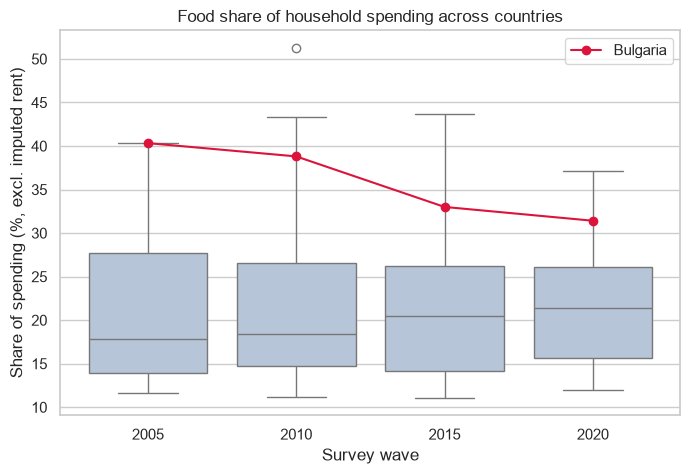

In [24]:
food = "Food and non-alcoholic beverages"
food_df = analysis[analysis["category"] == food]

years = sorted(food_df["year"].unique())
pos = {y: i for i, y in enumerate(years)}

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=food_df, x="year", y="share_excl_pct", color="lightsteelblue", ax=ax)

# Highlight Bulgaria
bg_food = food_df[food_df["country"] == "Bulgaria"].sort_values("year")
ax.plot(
    [pos[y] for y in bg_food["year"]],
    bg_food["share_excl_pct"],
    "o-",
    color="crimson",
    label="Bulgaria",
)

ax.set_title("Food share of household spending across countries")
ax.set_xlabel("Survey wave")
ax.set_ylabel("Share of spending (%, excl. imputed rent)")
ax.legend()
plt.show()

**Observations.**

- Food is the largest spending category in every survey wave, at roughly 21-22% of the budget
  on average, followed by housing (14.7% to 17.0%) and transport (about 14%).
- The housing share grows over time, while clothing (6.7% to 5.3%) and recreation
  (9.0% to 7.5%) decline and health grows slightly (3.9% to 4.6%).
- Bulgaria's food share (40.3% in 2005, 31.4% in 2020) is above the upper quartile of the
  countries in every wave, but the gap narrows: Bulgaria's share falls by about 9 percentage
  points while the median across countries rises slightly (from about 18% to about 21%).

*Caveat:* the averages are unweighted means over countries, and the set of countries differs
between waves (24, 32, 34 and 28 countries), so small changes between waves should not be
read as a clean trend.

## 6. Bulgaria vs European Countries


### 6.1 Ranking of countries by food share (2020)

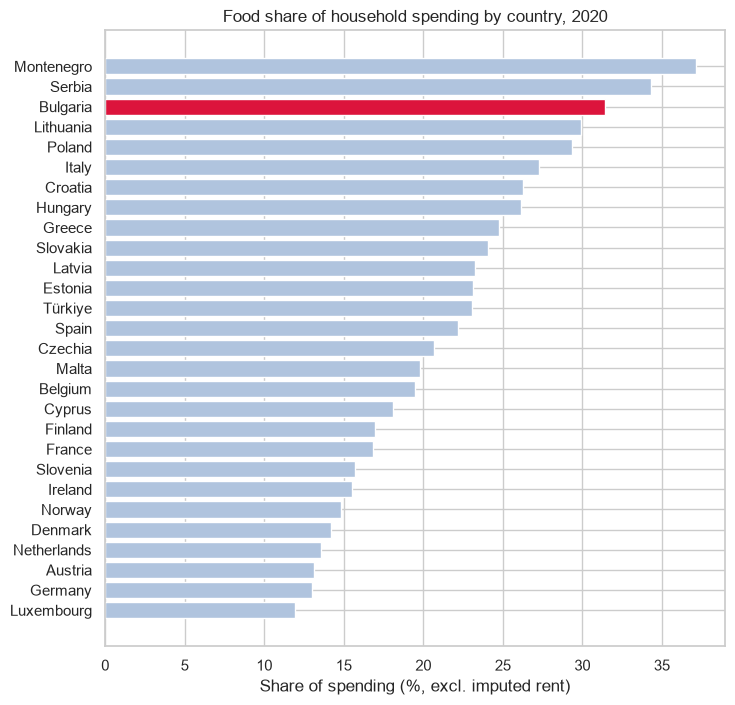

Bulgaria ranks 3 of 28 countries


In [25]:
food_2020 = (
    analysis[(analysis["year"] == 2020) & (analysis["category"] == food)]
    .sort_values("share_excl_pct")
)

# Highlight Bulgaria
colors = ["crimson" if c == "Bulgaria" else "lightsteelblue" for c in food_2020["country"]]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(food_2020["country"], food_2020["share_excl_pct"], color=colors)
ax.set_title("Food share of household spending by country, 2020")
ax.set_xlabel("Share of spending (%, excl. imputed rent)")
plt.show()

# Bulgaria's rank (1 = highest food share)
ranked = food_2020.sort_values("share_excl_pct", ascending=False).reset_index(drop=True)
rank = ranked.index[ranked["country"] == "Bulgaria"][0] + 1
print("Bulgaria ranks", rank, "of", len(ranked), "countries")

In [26]:
# Bulgaria: food share and GDP per capita (PPP) across the survey waves
bg_trend = (
    analysis[(analysis["country"] == "Bulgaria") & (analysis["category"] == food)]
    [["year", "share_excl_pct", "gdp_pc_ppp"]]
    .round(1)
)
bg_trend

,year,share_excl_pct,gdp_pc_ppp
13,2005,40.3,17678.0
14,2010,38.8,21724.3
15,2015,33.0,24562.6
16,2020,31.4,28521.2


**Observation.** Between 2005 and 2020, Bulgaria's GDP per capita (PPP, constant 2021 international dollars) increased from approximately 17,678 to 28,521, while the food share of household spending decreased from 40.3% to 31.4%. This pattern is consistent with Engel's law, although four observations alone cannot establish the relationship. The relationship is tested across countries in Section 8. Since GDP is expressed in constant 2021 international dollars, the series is adjusted for inflation, allowing meaningful comparisons over time.

### 6.2 Spending profile: Bulgaria vs the other countries (2020)

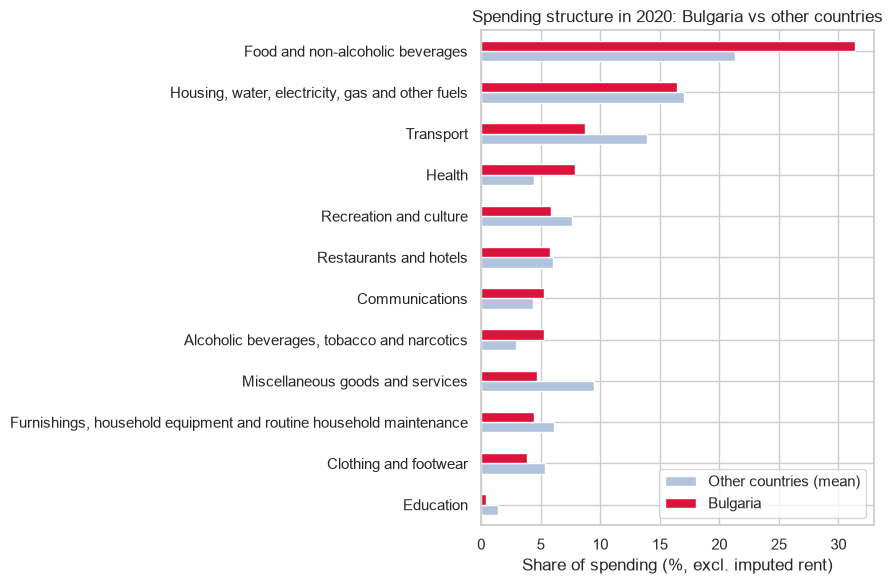

In [27]:
data_2020 = analysis[analysis["year"] == 2020].copy()
data_2020["group"] = data_2020["country"].where(
    data_2020["country"] == "Bulgaria", "Other countries (mean)"
)

profile = (
    data_2020.groupby(["category", "group"])["share_excl_pct"]
    .mean()
    .unstack("group")
    .sort_values("Bulgaria")
)

ax = profile[["Other countries (mean)", "Bulgaria"]].plot.barh(
    figsize=(9, 6), color=["lightsteelblue", "crimson"]
)
ax.set_title("Spending structure in 2020: Bulgaria vs other countries")
ax.set_xlabel("Share of spending (%, excl. imputed rent)")
ax.set_ylabel("")
ax.legend(title=None, loc="lower right")
plt.tight_layout()
plt.show()

**Observation.** Compared with the average of the other countries in 2020, Bulgarian
households spend a much larger share on food and a larger share on health and on alcohol and
tobacco. They spend a smaller share on transport, recreation and culture, clothing,
household furnishings and miscellaneous goods and services. The housing share (excluding
imputed rent) is similar. This is the typical pattern of a lower-income country, where basic
needs take a larger part of the budget.

## 7. Clustering of Countries


### 7.1 Feature matrix and nearest countries

Each country is described by a vector of 12 spending shares (2020, excluding imputed rent).
The similarity of two countries is the Euclidean distance between their vectors:
`d(a, b) = sqrt(sum_k (a_k - b_k)^2)`, where `k` runs over the 12 categories.

In [28]:
# One row per country, one column per spending category (2020)
features = (
    analysis[analysis["year"] == 2020]
    .pivot(index="country", columns="category", values="share_excl_pct")
)
print(features.shape)   # (countries, categories)

# Euclidean distance of every country to Bulgaria
dist_to_bg = ((features - features.loc["Bulgaria"]) ** 2).sum(axis=1) ** 0.5
dist_to_bg.drop("Bulgaria").sort_values().head(5).round(1)

(28, 12)


country
Lithuania    5.5
Serbia       5.6
Poland       5.9
Hungary      8.2
Italy        8.9
dtype: float64

**Observation.** In 2020, the countries with spending structures closest to Bulgaria are Lithuania, Serbia and Poland (Euclidean distances of approximately 5.5–5.9), followed by Hungary and Italy. Most of these countries are from Central and Eastern Europe and have broadly similar income levels. The Euclidean distance measures the overall difference between countries across all included COICOP expenditure categories, rather than the difference in any single category.

### 7.2 K-means clustering

Each category is standardised (z-score) so that every category has the same weight. The number
of clusters k is chosen with the silhouette score, which measures how well each country fits
its own cluster compared with the nearest other cluster (values from -1 to 1, higher is better).

In [29]:
X = StandardScaler().fit_transform(features)

# Silhouette score for k = 2..8 (fixed random_state for reproducibility)
scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels)

pd.Series(scores, name="silhouette").round(3)

2    0.205
3    0.213
4    0.171
5    0.167
6    0.175
7    0.166
8    0.117
Name: silhouette, dtype: float64

**Choice of k.** The silhouette score is highest for k = 3 (0.213), but only slightly above
k = 2 (0.205), and all values are low (below 0.25). The countries therefore do not form clearly
separated groups; the clusters describe regions of a continuum rather than distinct types.
We use k = 3 as a practical compromise.

In [30]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)

clusters = features.copy()
clusters["cluster"] = km.labels_

# Members of each cluster
for c, members in clusters.groupby("cluster"):
    print(f"Cluster {c} ({len(members)} countries):", ", ".join(sorted(members.index)))

# Average share of the main categories per cluster
main_cols = [food, "Housing, water, electricity, gas and other fuels", "Transport"]
clusters.groupby("cluster")[main_cols].mean().round(1)

Cluster 0 (13 countries): Bulgaria, Croatia, Czechia, Estonia, Hungary, Italy, Latvia, Lithuania, Montenegro, Poland, Serbia, Slovakia, Türkiye
Cluster 1 (11 countries): Austria, Belgium, Denmark, Finland, France, Germany, Ireland, Luxembourg, Netherlands, Norway, Slovenia
Cluster 2 (4 countries): Cyprus, Greece, Malta, Spain


category,Food and non-alcoholic beverages,"Housing, water, electricity, gas and other fuels",Transport
cluster,,,
0,27.4,17.2,12.0
1,15.0,18.1,16.0
2,21.2,13.0,13.2


### 7.3 PCA visualisation

Principal component analysis (PCA) projects the 12-dimensional country vectors onto the two
orthogonal directions of largest variance (the principal components), so that the clusters can
be inspected in a plane.

Explained variance ratio: [0.37 0.21]


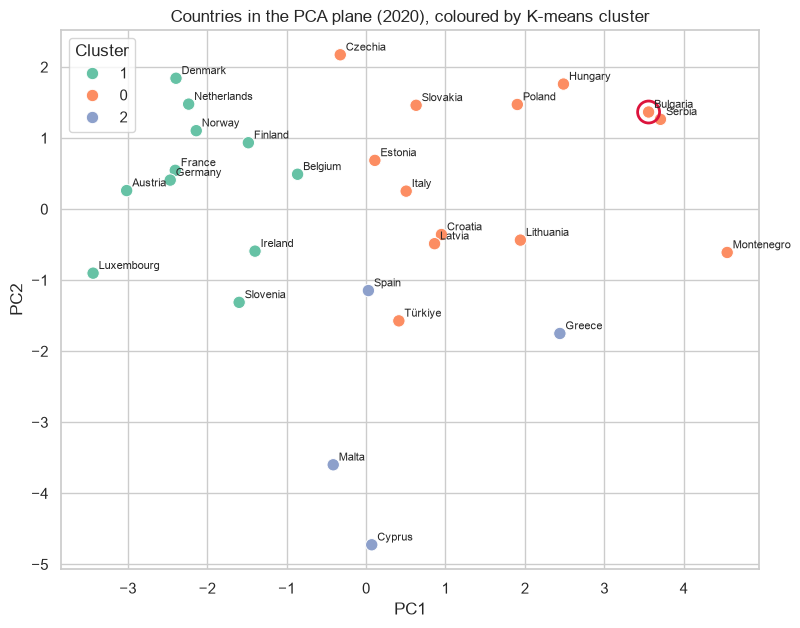

In [31]:
pca = PCA(n_components=2)
coords = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(2))

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(
    x=coords[:, 0], y=coords[:, 1],
    hue=clusters["cluster"].astype(str), palette="Set2", s=80, ax=ax,
)
for name, (x, y) in zip(features.index, coords):
    ax.annotate(name, (x, y), fontsize=8, xytext=(4, 3), textcoords="offset points")

# Circle Bulgaria
bg_i = list(features.index).index("Bulgaria")
ax.scatter(coords[bg_i, 0], coords[bg_i, 1], s=250, facecolors="none",
           edgecolors="crimson", linewidths=2)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Countries in the PCA plane (2020), coloured by K-means cluster")
ax.legend(title="Cluster")
plt.show()

**Observation.** The first two principal components explain 37% and 21% of the variance (58% in total). PC1 broadly separates higher-income Western and Northern European countries (left) from lower-income countries such as Bulgaria, Serbia and Montenegro (right). Bulgaria lies within a cluster of Central and Eastern European countries and is positioned close to Serbia. Cluster 2 consists of Cyprus, Malta, Greece and Spain. The relatively low silhouette scores indicate that the clustering structure is not clearly separated and is sensitive to the choice of k.

In [32]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features.columns,
    columns=["PC1", "PC2"],
).round(2)
loadings.sort_values("PC1")

,PC1,PC2
category,,
Recreation and culture,-0.36,0.19
Miscellaneous goods and services,-0.33,0.04
Transport,-0.33,-0.21
"Furnishings, household equipment and routine household maintenance",-0.27,-0.06
Restaurants and hotels,-0.20,-0.42
"Housing, water, electricity, gas and other fuels",-0.11,0.52
Education,0.06,-0.50
Clothing and footwear,0.12,-0.39
Health,0.27,-0.16


**Interpretation of the components.** PC1 contrasts necessities (food, communications, alcohol
and tobacco, health) with discretionary spending (recreation and culture, miscellaneous
services, transport, furnishings, restaurants). Countries on the right, including Bulgaria,
therefore spend a larger part of their budget on necessities. PC2 contrasts housing with
education, restaurants and clothing. The sign of a principal component is arbitrary, so only
the relative pattern is interpreted.

## 8. Regression: Food Share vs Income per Capita


### 8.1 The relationship: Engel's law

Engel's law states that the share of household expenditure spent on food decreases as income rises. Income effects are generally proportional rather than absolute (an additional 1,000 dollars matters much more at an income level of 5,000 than at 50,000). Therefore, we model the food expenditure share `s` as a linear function of the natural logarithm of GDP per capita:

`s_i = b0 + b1 * ln(GDP_i) + e_i`

where GDP per capita is measured in constant 2021 international dollars (PPP).

Engel's law predicts a negative relationship, meaning that `b1 < 0`.

The analysis uses country-year observations from 2005, 2010, 2015 and 2020.

(118, 5)


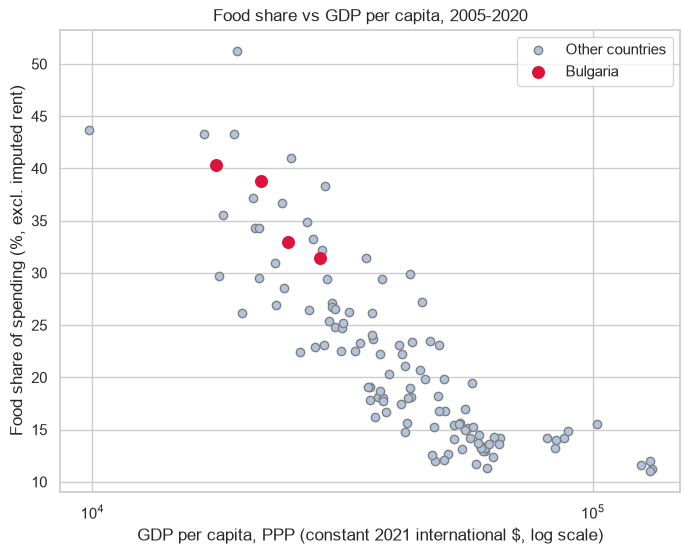

In [33]:
food_reg = analysis[analysis["category"] == food][
    ["country", "year", "share_excl_pct", "gdp_pc_ppp"]
].copy()
food_reg["log_gdp"] = np.log(food_reg["gdp_pc_ppp"])
print(food_reg.shape)

others = food_reg[food_reg["country"] != "Bulgaria"]
bg = food_reg[food_reg["country"] == "Bulgaria"]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(others["gdp_pc_ppp"], others["share_excl_pct"],
           color="lightsteelblue", edgecolor="grey", label="Other countries")
ax.scatter(bg["gdp_pc_ppp"], bg["share_excl_pct"],
           color="crimson", s=70, label="Bulgaria")
ax.set_xscale("log")
ax.set_xlabel("GDP per capita, PPP (constant 2021 international $, log scale)")
ax.set_ylabel("Food share of spending (%, excl. imputed rent)")
ax.set_title("Food share vs GDP per capita, 2005-2020")
ax.legend()
plt.show()

**Observation.** The food expenditure share generally decreases as GDP per capita increases. On a logarithmic GDP scale, the relationship appears approximately linear, although it becomes flatter at higher income levels. Bulgaria's observations are located in the upper part of the scatter plot, indicating a relatively high food expenditure share compared with many other countries at similar income levels.

### 8.2 OLS regression

We estimate the model `s = b0 + b1 * ln(GDP) + e` using ordinary least squares (OLS). Since each country can appear up to four times (once per survey wave), observations from the same country may be correlated. Therefore, standard errors are clustered by country to account for within-country dependence.

The coefficient `b1` measures the change in the food expenditure share, in percentage points, associated with a one-unit increase in the natural logarithm of GDP per capita. A doubling of GDP per capita is associated with a change of `b1 * ln(2)` percentage points in the food expenditure share.

In [34]:
# Cluster-robust standard errors: observations of the same country are correlated
groups = pd.factorize(food_reg["country"])[0]
model = smf.ols("share_excl_pct ~ log_gdp", data=food_reg).fit(
    cov_type="cluster", cov_kwds={"groups": groups}
)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:         share_excl_pct   R-squared:                       0.714
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     60.27
Date:                Sat, 28 Nov 2026   Prob (F-statistic):           6.06e-09
Time:                        16:14:04   Log-Likelihood:                -350.19
No. Observations:                 118   AIC:                             704.4
Df Residuals:                     116   BIC:                             709.9
Df Model:                           1                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    191.1661     21.824      8.759      0.0

**Result.** The coefficient of ln(GDP) is -15.945 (cluster-robust standard error 2.054; 95% confidence interval from -19.971 to -11.920), and R-squared is 0.714. A doubling of GDP per capita is associated with a decrease in the food expenditure share of approximately 15.945 * ln(2) = 11.05 percentage points, which is consistent with Engel's law.

This is an association, not a causal effect, and GDP per capita is only a proxy for household income.

In [35]:
food_reg["fitted"] = model.fittedvalues
food_reg["residual"] = model.resid

# Bulgaria: actual vs predicted food share
food_reg[food_reg["country"] == "Bulgaria"][
    ["year", "share_excl_pct", "fitted", "residual"]
].round(1)

,year,share_excl_pct,fitted,residual
13,2005,40.3,35.2,5.1
14,2010,38.8,31.9,6.9
15,2015,33.0,30.0,3.0
16,2020,31.4,27.6,3.8


**Bulgaria relative to the model.** Bulgaria lies above the fitted line in all four waves: its food share is 5.1 percentage points higher than predicted in 2005, 6.9 points higher in 2010, 3.0 points higher in 2015 and 3.8 points higher in 2020. In 2020 the model predicts a food share of 27.6%, but the observed share is 31.4%. The gap does not prove a cause. Possible explanations include that GDP per capita overstates the income that actually reaches households, or that food is relatively expensive compared with incomes in Bulgaria; testing them would require income and price data that are not part of this project.

### 8.3 Model diagnostics

We assess the OLS model using residual diagnostic plots. The residuals-versus-fitted plot is used to check for systematic patterns that may indicate non-linearity or heteroscedasticity (non-constant variance). The Q-Q plot is used to assess whether the residuals are approximately normally distributed. These diagnostics help evaluate the suitability of the linear model and identify potential limitations.

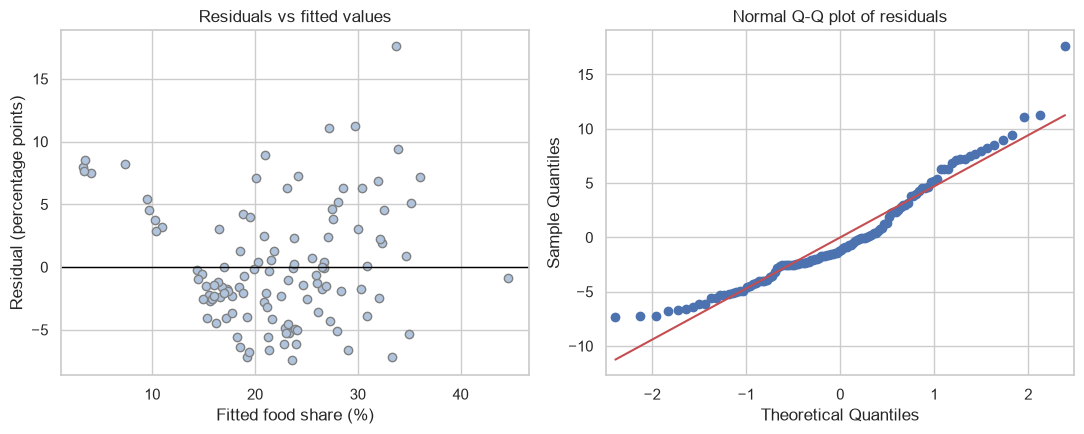

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Residuals vs fitted values
axes[0].scatter(food_reg["fitted"], food_reg["residual"], color="lightsteelblue", edgecolor="grey")
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Fitted food share (%)")
axes[0].set_ylabel("Residual (percentage points)")
axes[0].set_title("Residuals vs fitted values")

# Normal Q-Q plot of residuals
sm.qqplot(food_reg["residual"], line="s", ax=axes[1])
axes[1].set_title("Normal Q-Q plot of residuals")

plt.tight_layout()
plt.show()

**Diagnostics.** The residuals show no strong funnel shape, and the Q-Q plot is close to the reference line except for a heavy right tail (a few large positive residuals). However, for the richest countries the linear model predicts food shares that are too low: for Luxembourg it predicts only 3.2-4.0%, while the observed shares are 11.1-12.0%, and for Ireland (2020) and Norway (2020) the observed shares are 15.5% and 14.8% against predictions of 7.3% and 9.4%. The residuals there are systematically positive. The food share seems to level off at high incomes, which a straight line in ln(GDP) cannot capture. A log-log specification, which keeps predictions positive, is tested next.

### 8.4 Alternative specification: log-log model

As an alternative specification, we estimate a log-log model:

`ln(s_i) = b0 + b1 * ln(GDP_i) + e_i`

In this model, `b1` is an elasticity: a 1% increase in GDP per capita is associated with an approximate `b1%` change in the food expenditure share. The predicted values are transformed back to the original scale using the exponential function (`exp(fitted)`), ensuring positive predictions.

The two models are compared using RMSE calculated on the original percentage scale. Their R-squared values are not directly comparable because the dependent variables are expressed on different scales.

In [37]:
food_reg["log_share"] = np.log(food_reg["share_excl_pct"])

model2 = smf.ols("log_share ~ log_gdp", data=food_reg).fit(
    cov_type="cluster", cov_kwds={"groups": groups}
)
print(model2.params.round(3))
print(model2.conf_int().round(3))

# Compare both models on the original scale (RMSE in percentage points)
pred2 = np.exp(model2.fittedvalues)
rmse1 = np.sqrt(((food_reg["share_excl_pct"] - model.fittedvalues) ** 2).mean())
rmse2 = np.sqrt(((food_reg["share_excl_pct"] - pred2) ** 2).mean())
print(f"RMSE semi-log: {rmse1:.2f}, log-log: {rmse2:.2f}")

Intercept    10.530
log_gdp      -0.708
dtype: float64
               0       1
Intercept  9.120  11.940
log_gdp   -0.842  -0.575
RMSE semi-log: 4.71, log-log: 4.44


In [38]:
food_reg["pred_loglog"] = pred2
food_reg[food_reg["country"].isin(["Luxembourg", "Ireland", "Norway"]) & (food_reg["year"] == 2020)][
    ["country", "share_excl_pct", "fitted", "pred_loglog"]
].round(1)

,country,share_excl_pct,fitted,pred_loglog
79,Ireland,15.5,7.3,10.6
96,Luxembourg,12.0,3.4,8.9
119,Norway,14.8,9.4,11.7


**Result.** The elasticity of the food expenditure share with respect to GDP per capita is -0.708 (95% confidence interval: -0.842 to -0.575). This indicates that a 1% increase in GDP per capita is associated with an approximately 0.71% decrease in the food expenditure share. A doubling of GDP per capita is associated with a food share approximately 38.8% lower (`2^(-0.708) ≈ 0.612`).

In the log-log model Bulgaria's food share is also above the predicted value in all four waves: by 3.6 percentage points in 2005, 7.1 in 2010, 3.9 in 2015 and 5.2 in 2020.


In [39]:
food_reg["resid_loglog"] = food_reg["share_excl_pct"] - pred2
food_reg[food_reg["country"] == "Bulgaria"][["year", "share_excl_pct", "resid_loglog"]].round(1)

,year,share_excl_pct,resid_loglog
13,2005,40.3,3.6
14,2010,38.8,7.1
15,2015,33.0,3.9
16,2020,31.4,5.2


## 9. Conclusions, Limitations and Next Steps


### 9.1 Answers to the research questions

**1. How does the spending structure in Bulgaria differ from other countries?**
In 2020 Bulgarian households spent 31.4% of their budget on food (excluding imputed rent),
compared with a cross-country average of about 22%. Bulgaria had the third-highest food share
among the 28 countries in the sample, behind only Montenegro and Serbia, and the highest among
the EU member states in the sample. Bulgarian households also spent larger shares on health and
on alcohol and tobacco, and smaller shares on transport, recreation and culture, clothing,
household furnishings and miscellaneous services.

**2. How has the structure changed over time?**
Between 2005 and 2020 Bulgaria's food share fell from 40.3% to 31.4% while its GDP per capita
(PPP, constant 2021 international dollars) rose from about 17,700 to about 28,500.

**3. Which countries are closest to Bulgaria?**
By Euclidean distance of the spending shares in 2020 the closest countries are Lithuania,
Serbia and Poland (distance of about 5.5-5.9 percentage points), followed by Hungary and Italy.
K-means clustering with k = 3 places Bulgaria in a cluster of Central and Eastern European
countries with a high share of spending on necessities.

**4. Does Engel's law hold?**
Yes. Across country-years, the food share falls strongly with GDP per capita: the semi-log
model gives -15.9 percentage points per unit of ln(GDP) (R-squared 0.71), and the log-log model
gives an elasticity of -0.71 (95% confidence interval from -0.84 to -0.58). Bulgaria lies above
the fitted relationship in all four waves (by 3.0 to 6.9 percentage points in the semi-log model),
i.e. it spends more on food than other countries with the same GDP per capita.

### 9.2 Limitations

- **Few comparable waves.** The Household Budget Survey is conducted roughly every five years,
  so only four waves (2005, 2010, 2015, 2020) are comparable, and the set of countries differs
  between waves (24, 32, 34 and 28 countries).
- **Imputed rent.** Countries treat it differently (for example Czechia and Malta report 0),
  and countries that do not report it, such as Romania and Portugal in 2020, are missing from
  the analysis. The adjusted shares depend on this correction.
- **GDP is only a proxy for household income.** It includes income that does not reach
  households. It is measured in constant 2021 international dollars (PPP), so it is adjusted
  for inflation, but it still does not show how income is distributed within a country.
- **Unweighted averages.** Country averages are not weighted by population, and the shares
  are compositional (they add up to 100%).
- **Weak cluster structure.** The silhouette scores are low (at most 0.21), so the clusters
  describe regions of a continuum rather than distinct groups.
- **Association, not causation.** The regression uses repeated observations of the same
  countries (handled with clustered standard errors) and shows mild non-normality of residuals.
- **Data quality flags.** A few observations are flagged as low reliability (for example
  education in Bulgaria in 2005); they are very small shares and do not affect the results.

### 9.3 Next steps

- Add household income or wage data, to test whether the gap between Bulgaria and the fitted relationship disappears.
- Fit a panel regression with country fixed effects, and add price data (HICP) to separate
  price effects from consumption volumes.
- Repeat the clustering for other waves (for example 2015) and with other methods
  (for example hierarchical clustering) to test its stability.


## 10. Sources and Licences

### Datasets

| # | Source | Dataset | Content | URL | Downloaded | Licence |
|---|---|---|---|---|---|---|
| 1 | Eurostat | `hbs_str_t211` | Structure of consumption expenditure by COICOP category (Household Budget Survey), in per mille | https://ec.europa.eu/eurostat/databrowser/view/hbs_str_t211/default/table | 15 November 2026 | CC BY 4.0 (Eurostat reuse policy) |
| 2 | World Bank, World Development Indicators | `NY.GDP.PCAP.PP.KD` | GDP per capita, PPP (constant 2021 international $) | https://data.worldbank.org/indicator/NY.GDP.PCAP.PP.KD | 24 November 2026 | CC BY 4.0 |

The two sources are published by different institutions and are independent of each other. The raw files are stored unchanged in `data/raw/`; the cleaned and merged data are in `data/processed/`.

Attribution: *Source: Eurostat* and *Source: World Bank, World Development Indicators*.

### Literature

- Engel, E. (1857). Die Productions- und Consumtionsverhältnisse des Königreichs Sachsen. *Zeitschrift des Statistischen Bureaus des Königlich Sächsischen Ministeriums des Innern*, 8-9.

### Software

Python with pandas, NumPy, Matplotlib, seaborn, scikit-learn and statsmodels (see `requirements.txt`).